In [ ]:
!unzip -q "vegetable dataset.zip.zip"
!ls

 sample_data  'vegetable dataset'  'vegetable dataset.zip.zip'


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)


In [ ]:
import os
for c in os.listdir("vegetable dataset"):
    print(c, len(os.listdir(os.path.join("vegetable dataset", c))))

tamato 23
potato 17
onion 21


In [ ]:
import tensorflow as tf

data_dir = "vegetable dataset"

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training",
    seed=42, image_size=(224, 224), batch_size=16)
test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation",
    seed=42, image_size=(224, 224), batch_size=16)

class_names = train_ds.class_names
print("Classes:", class_names)

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(class_names), activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.fit(train_ds, epochs=5)

loss, acc = model.evaluate(test_ds)
print("Model Accuracy:", round(acc * 100, 2), "%")

model.save("vegetable_model.keras")

Found 61 files belonging to 3 classes.
Using 49 files for training.
Found 61 files belonging to 3 classes.
Using 12 files for validation.
Classes: ['onion', 'potato', 'tamato']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 402ms/step - accuracy: 0.6531 - loss: 0.9631
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 377ms/step - accuracy: 0.8571 - loss: 0.4343
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 380ms/step - accuracy: 0.9184 - loss: 0.2850
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 363ms/step - accuracy: 1.0000 - loss: 0.1005
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 653ms/step - accuracy: 1.0000 - loss: 0.0581
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.9167 - loss: 0.2432
Model Accuracy: 91.67 %


In [ ]:
from google.colab import files
files.download("vegetable_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile, os
with zipfile.ZipFile("vegetable dataset.zip.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

# Handle the extra wrapper folder from zipping
root = "dataset"
contents = os.listdir(root)
if len(contents) == 1 and os.path.isdir(os.path.join(root, contents[0])):
    root = os.path.join(root, contents[0])

classes = sorted(os.listdir(root))
print("Using folder:", root)
print("Classes found:", classes)

Using folder: dataset/vegetable dataset
Classes found: ['onion', 'potato', 'tamato']


In [12]:
DATASET_DIR = "/content/dataset"

import os

print(os.listdir(DATASET_DIR))

FileNotFoundError: [Errno 2] No such file or directory: '/content/dataset'

In [ ]:
import os

# Define the dataset directory using the 'root' variable from the previous cell
DATASET_DIR = root if 'root' in globals() else "dataset/vegetable dataset"

CLASSES = ["onion", "potato", "tamato"]

for class_name in CLASSES:
    folder = os.path.join(DATASET_DIR, class_name)

    if not os.path.isdir(folder):
        print(f"Missing folder: {folder}")
        continue

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"Class {class_name}: {len(images)} images")

Class onion: 21 images
Class potato: 17 images
Class tamato: 23 images


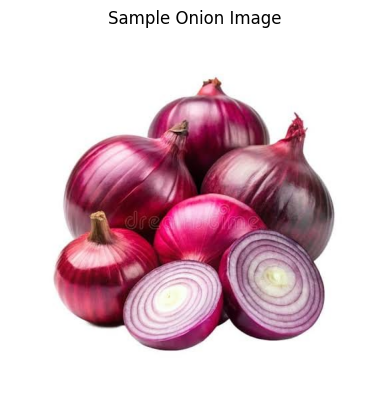

Image shape: (554, 554, 3)
Example pixel: [255 255 255]


In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

sample_folder = os.path.join(DATASET_DIR, "onion")

sample_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

if not sample_files:
    raise ValueError("No images found in onion class.")

sample_path = os.path.join(sample_folder, sample_files[0])
image = cv2.imread(sample_path)

if image is None:
    raise ValueError("Image could not be loaded.")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(rgb_image)
plt.title("Sample Onion Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Example pixel:", image[0, 0])

Original shape: (554, 554, 3)
Resized shape: (64, 64, 3)


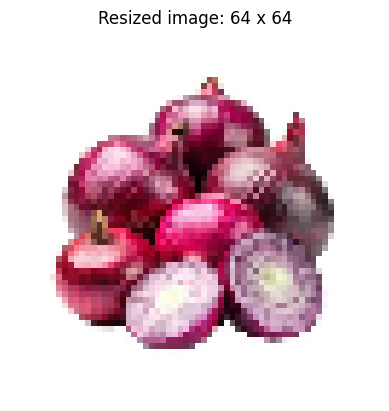

In [ ]:
resized = cv2.resize(image, (64, 64))

print("Original shape:", image.shape)
print("Resized shape:", resized.shape)

plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized image: 64 x 64")
plt.axis("off")
plt.show()

In [ ]:
features = resized.flatten()

print("Number of features:", features.shape[0])

Number of features: 12288


In [ ]:

import numpy as np

features = features.astype(np.float32) / 255.0

print("Minimum pixel value:", features.min())
print("Maximum pixel value:", features.max())

Minimum pixel value: 0.0
Maximum pixel value: 0.003921569


In [ ]:
import os
import cv2
import numpy as np

def load_dataset(dataset_dir):
    X = []
    y = []

    # Dynamically find classes from the subfolders
    class_names = sorted([d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))])
    print("Found classes:", class_names)

    for class_idx, class_name in enumerate(class_names):
        folder = os.path.join(dataset_dir, class_name)

        for filename in os.listdir(folder):
            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            image_path = os.path.join(folder, filename)
            image = cv2.imread(image_path)

            if image is None:
                print("Skipping unreadable image:", image_path)
                continue

            image = cv2.resize(image, (64, 64))
            features = image.astype(np.float32).flatten() / 255.0

            X.append(features)
            y.append(class_idx)

    if len(X) == 0:
        raise ValueError(
            "No images were loaded. Check your dataset path."
        )

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.int64)
    )

X, y = load_dataset(DATASET_DIR)

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Classes found:", np.unique(y))

Found classes: ['onion', 'potato', 'tamato']
Feature matrix shape: (61, 12288)
Label array shape: (61,)
Classes found: [0 1 2]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 48
Testing samples: 13


In [ ]:
from sklearn.svm import SVC

model = SVC(kernel="linear")
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [ ]:
y_pred = model.predict(X_test)

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(f"Actual: {actual}, Predicted: {predicted}")

Actual: 0, Predicted: 2
Actual: 2, Predicted: 1
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 2, Predicted: 2
Actual: 0, Predicted: 0
Actual: 2, Predicted: 2
Actual: 0, Predicted: 0
Actual: 1, Predicted: 1
Actual: 2, Predicted: 2


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 84.62%


In [9]:
from google.colab import files
import cv2, matplotlib.pyplot as plt

print("Upload a photo of a tomato, potato, or onion")
uploaded = files.upload()
fname = list(uploaded.keys())[0]

img = cv2.imread(fname)

# Check if image loaded successfully
if img is None:
    raise ValueError(f"Failed to load '{fname}'. Please make sure you uploaded a valid image file (JPG, PNG).")

small = cv2.resize(img, (64, 64))
inp = small.flatten().astype("float32") / 255.0

pred = model.predict([inp])[0]
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Model says: {CLASSES[pred]}")
plt.axis("off")
plt.show()

Upload a photo of a tomato, potato, or onion


Saving .potato.jpg to .potato (2).jpg


NameError: name 'model' is not defined